# Food Recognition with Convolutional Neural Networks

## Problem definition

This project investigates multiclass image classification using Food-101, a public dataset of 101,000 images across 101 food categories. The task is to predict one food category from an RGB image using a convolutional neural network implemented in PyTorch and trained from scratch.

The main experiment compares a compact baseline CNN with a wider CNN, changing only the channel widths while keeping the remaining training settings fixed. Supplementary experiments investigate label smoothing, dropout, and an increased maximum training budget through separate comparisons.

Performance is evaluated using top-1 accuracy and cross-entropy loss. Validation loss determines checkpoint selection, while class-level recall, frequent confusion pairs, and sampled errors provide additional insight into the wider CNN's limitations.

The objective is to explain the relationship between model capacity, regularization, training duration, predictive performance, and computational cost.

In [1]:
import json
import platform
import sys

from itertools import islice
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import random
import seaborn as sns
import torch
import torchvision

from sklearn.model_selection import train_test_split
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import transforms
from torchvision.datasets import Food101
from tqdm.auto import tqdm

In [2]:
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

print("Python:", sys.version.split()[0])
print("Interpreter:", sys.executable)
print("Architecture:", platform.machine())
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("MPS built:", torch.backends.mps.is_built())
print("MPS available:", torch.backends.mps.is_available())
print("Selected device:", device)

# Verify that computation works on the selected device.
x = torch.randn(32, 32, device=device)
result = x @ x.T
print("Computation successful:", result.shape)

Python: 3.14.0
Interpreter: /Users/ashlabs/Projects/Masters in AI/github/food-recognition-deep-learning/.venv/bin/python
Architecture: arm64
PyTorch: 2.14.1
Torchvision: 0.29.1
MPS built: True
MPS available: True
Selected device: mps
Computation successful: torch.Size([32, 32])


## Dataset acquisition

This project uses Food-101, a public dataset containing 101,000 images across 101 food categories. The official split provides 75,750 training images and 25,250 test images.

A validation partition will be created from the official training split. The official test split will remain untouched until the model configurations and evaluation procedure are finalized.

The training data contains label noise and other image-quality issues, which will be considered during error analysis.

Source [Food-101 - Mining Discriminative Components with Random Forests](https://data.vision.ee.ethz.ch/cvl/datasets_extra/food-101/)

In [3]:
ROOT_FOLDER = Path.cwd()
DATA_FOLDER = ROOT_FOLDER / "data" / "raw"

In [4]:
DATA_FOLDER.mkdir(parents=True, exist_ok=True)

In [5]:
ds_train = Food101(
    root=str(DATA_FOLDER),
    split="train",
    download=True
)

In [6]:
print(f"Training images: {len(ds_train)}")
print(f"Number of classes: {len(ds_train.classes)}")
print("First 10 classes: ", ds_train.classes[:10])

Training images: 75750
Number of classes: 101
First 10 classes:  ['apple_pie', 'baby_back_ribs', 'baklava', 'beef_carpaccio', 'beef_tartare', 'beet_salad', 'beignets', 'bibimbap', 'bread_pudding', 'breakfast_burrito']


## Dataset inspection

Representative training images are displayed in their original form to inspect appearance, dimensions, and labels. No preprocessing or augmentation is applied at this stage.

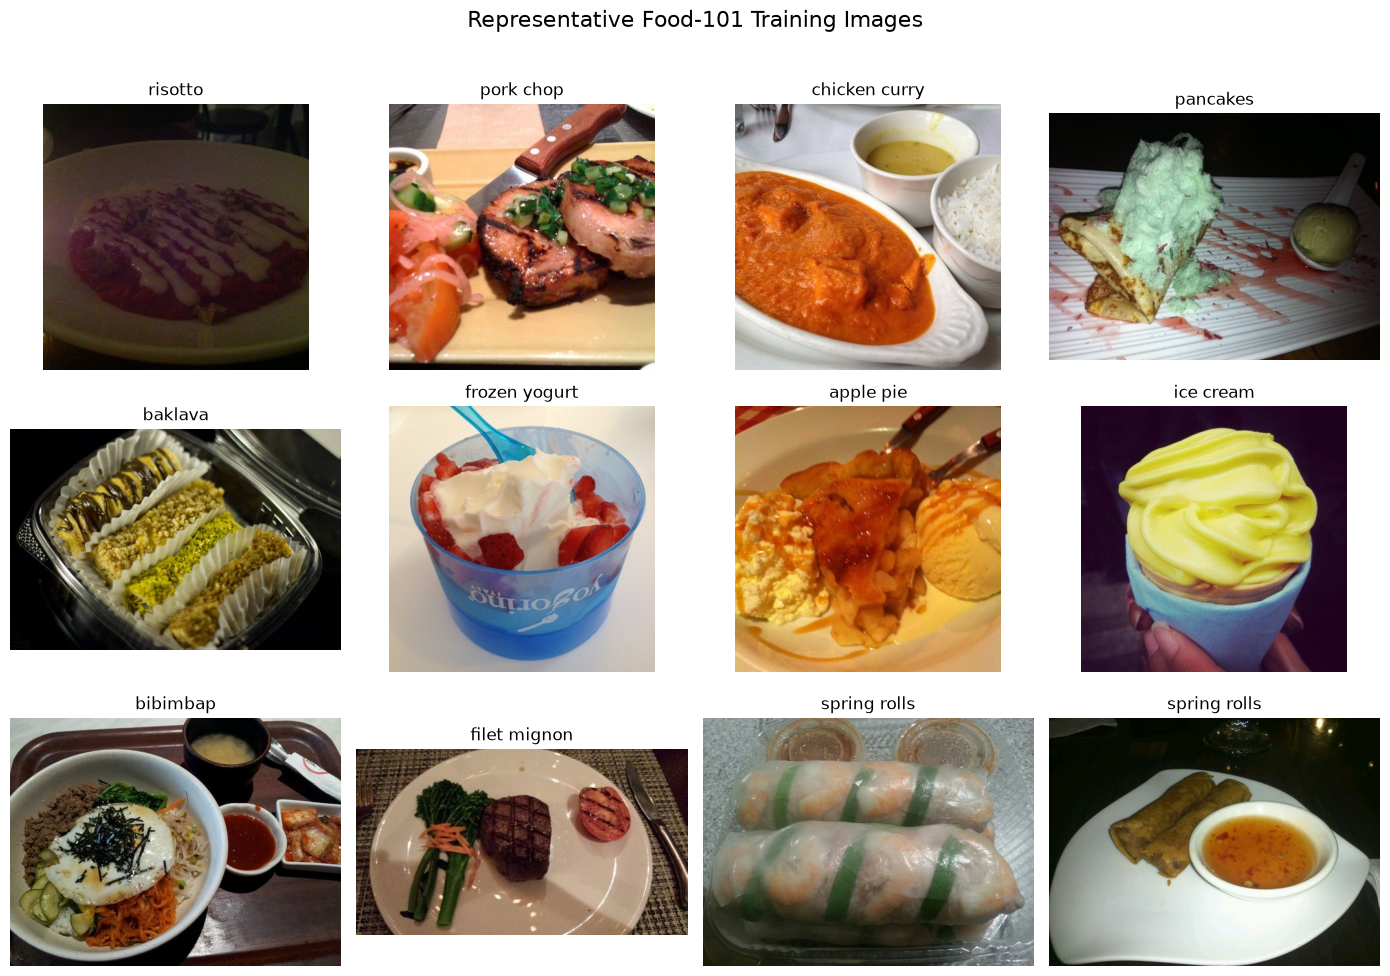

,index,class,width,height,mode
0,14592,risotto,512,512,RGB
1,3278,pork_chop,512,512,RGB
2,36048,chicken_curry,512,512,RGB
3,32098,pancakes,512,382,RGB
4,29256,baklava,512,342,RGB
5,18289,frozen_yogurt,512,512,RGB
6,13434,apple_pie,512,512,RGB
7,71482,ice_cream,512,512,RGB
8,11395,bibimbap,512,384,RGB
9,55302,filet_mignon,512,288,RGB


In [7]:
sample_range = random.Random(42)
sample_indices = sample_range.sample(range(len(ds_train)), 12)

fig, axes = plt.subplots(3,4,figsize=(14,10))
sample_details = []

for ax, index in zip(axes.flat, sample_indices):
    image, label = ds_train[index]
    class_name = ds_train.classes[label]

    sample_details.append({
        "index": index,
        "class": class_name,
        "width": image.width,
        "height": image.height,
        "mode": image.mode
    })

    ax.imshow(image)
    ax.set_title(class_name.replace("_", " "))
    ax.axis("off")

fig.suptitle("Representative Food-101 Training Images", fontsize=16)
fig.tight_layout(rect=(0, 0, 1, 0.96))

FIGURE_ROOT = ROOT_FOLDER / "figures"
FIGURE_ROOT.mkdir(parents=True, exist_ok=True)

fig.savefig(
    FIGURE_ROOT / "food101_training_samples.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

display(pd.DataFrame(sample_details))

## Training and validation split

The official training partition is divided into 80% training and 20% validation using stratified sampling with a fixed random seed. Both experimental configurations use exactly the same split.

Validation results will support model selection and training decisions. The official test partition is reserved for final evaluation.

In [8]:
labels = np.asarray(ds_train._labels, dtype=np.int64)
all_indices = np.arange(len(ds_train))

train_indices, val_indices = train_test_split(
    all_indices,
    test_size=0.20,
    random_state=42,
    stratify=labels
)

split_counts = pd.DataFrame(
    {
        "class": ds_train.classes,
        "training": np.bincount(
            labels[train_indices],
            minlength=len(ds_train.classes)
        ),
        "validation": np.bincount(
            labels[val_indices],
            minlength=len(ds_train.classes)
        )
    }
)

In [9]:
assert len(np.intersect1d(train_indices, val_indices)) == 0
assert len(train_indices) + len(val_indices) == len(ds_train)

# As per documentation, 750 training images are provided for each class. Verify 80:20 split between training and validation datasets
# Training = 750 * 0.8 = 600, validation = 750 *0.2 = 150
assert (split_counts["training"] == 600).all()
assert (split_counts["validation"] == 150).all()

In [10]:
# Save the split so subsequent runs can reuse.

SPLIT_FOLDER = ROOT_FOLDER / "splits"
SPLIT_FOLDER.mkdir(parents=True, exist_ok=True)

np.savez_compressed(
    SPLIT_FOLDER / "food101_train_val_seed42.npz",
    train_indices=train_indices,
    val_indices=val_indices
)

print(f"Training images: {len(train_indices)}")
print(f"Validation images: {len(val_indices)}")
print(f"Classes: {len(split_counts)}")
display(split_counts.head(20))

Training images: 60600
Validation images: 15150
Classes: 101


,class,training,validation
0,apple_pie,600,150
1,baby_back_ribs,600,150
2,baklava,600,150
3,beef_carpaccio,600,150
4,beef_tartare,600,150
5,beet_salad,600,150
6,beignets,600,150
7,bibimbap,600,150
8,bread_pudding,600,150
9,breakfast_burrito,600,150


## Image preprocessing and data loaders

Training images are randomly cropped and resized to 128 x 128 pixels, with random horizontal flips to introduce variation during training.

Validation images are resized while preserving aspect ratio, then center-cropped to 128 x 128 pixels. Validation does not use random augmentation.

Before normalization, RGB channel means and standard deviations will be calculated from the 60,600 training images only. This calculation will use deterministic resizing and center cropping, followed by conversion to tensors with pixel values in [0,1]. Random augmentation will not be applied when estimating these statistics.

The resulting training-derived statistics will be used to normalize training, validation, and test inputs. Both experimental configurations will use identical preprocessing and normalization.

An initial image size of 128 x 128 and batch size of 32 are used for the training pilot. These settings will be reviewed before the full experiment is finalized.

In [11]:
IMAGE_SIZE = 128
BATCH_SIZE = 32
SEED = 42

In [12]:
# Resize the shorter side to 144 pixels while preserving aspect ratio, then take a centered 128 × 128 crop to produce a consistent input shape.
# The extra margin avoids stretching rectangular images, but cropping may remove content near the edges. Convert pixels to tensors in [0, 1]
# without normalization or random augmentation so we can estimate training-channel statistics using the validation preprocessing.

statistics_transform = transforms.Compose([
    transforms.Resize(144),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor()
])

In [13]:
statistics_dataset = Food101(
    root=str(DATA_FOLDER),
    split="train",
    transform=statistics_transform,
    download=False
)

In [14]:
statistics_subset = Subset(
    statistics_dataset,
    train_indices.tolist()
)

In [15]:
statistics_loader = DataLoader(
    statistics_subset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

In [16]:
# Accumulate per-channel sums across all training pixels. Float64 reduces numerical error in the accumulated totals.
channel_sum = torch.zeros(3, dtype=torch.float64)
channel_squared_sum = torch.zeros(3, dtype=torch.float64)
pixel_count = 0

for batch_images, _ in tqdm(statistics_loader, desc="Calculating training channel statistics"):
    batch_images = batch_images.to(dtype=torch.float64)

    channel_sum += batch_images.sum(dim=(0, 2, 3))
    channel_squared_sum += batch_images.square().sum(dim=(0, 2, 3))

    pixel_count += (
        batch_images.shape[0]
        * batch_images.shape[2]
        * batch_images.shape[3]
    )

channel_mean = channel_sum / pixel_count
channel_variance = channel_squared_sum / pixel_count - channel_mean.square()
channel_std = channel_variance.clamp(min=0).sqrt()

Calculating training channel statistics:   0%|          | 0/1894 [00:00<?, ?it/s]

In [17]:
assert torch.isfinite(channel_mean).all().item()
assert torch.isfinite(channel_std).all().item()
assert (channel_std > 0).all().item()

In [18]:
TRAIN_MEAN = tuple(channel_mean.tolist())
TRAIN_STD = tuple(channel_std.tolist())

display(pd.DataFrame({
    "channel": ["red", "green", "blue"],
    "mean": TRAIN_MEAN,
    "standard_deviation": TRAIN_STD,
}))

print("Training images processed:", len(statistics_subset))
print("Pixels per channel:", pixel_count)

,channel,mean,standard_deviation
0,red,0.557411,0.257118
1,green,0.442900,0.260925
2,blue,0.328740,0.264169


Training images processed: 60600
Pixels per channel: 992870400


In [19]:
# Training uses random augmentation.
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(
        IMAGE_SIZE,
        scale=(0.7, 1.0),
        ratio=(0.8, 1.25)
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean=TRAIN_MEAN, std=TRAIN_STD)
])

In [20]:
# Validation uses deterministic preprocessing.
val_transform = transforms.Compose([
    transforms.Resize(144),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean=TRAIN_MEAN, std=TRAIN_STD)
])

In [21]:
# Separate instances let each split use its own transforms.
training_images = Food101(
    root=str(DATA_FOLDER),
    split="train",
    transform=train_transform,
    download=False
)

validation_images = Food101(
    root=str(DATA_FOLDER),
    split="train",
    transform=val_transform,
    download=False,
)

In [22]:
training_subset = Subset(training_images, train_indices.tolist())
validation_subset = Subset(validation_images, val_indices.tolist())

In [23]:
torch.manual_seed(SEED)
train_generator = torch.Generator().manual_seed(SEED)

In [24]:
train_loader = DataLoader(
    training_subset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    generator=train_generator
)

val_loader = DataLoader(
    validation_subset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

In [25]:
print("Training images:", len(training_subset))
print("Validation images:", len(validation_subset))
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training images: 60600
Validation images: 15150
Training batches: 1894
Validation batches: 474


In [26]:
images, targets = next(iter(val_loader))

assert images.shape == (BATCH_SIZE, 3, IMAGE_SIZE, IMAGE_SIZE)
assert images.dtype == torch.float32
assert targets.dtype == torch.int64
assert targets.min().item() >= 0
assert targets.max().item() < len(ds_train.classes)
assert torch.isfinite(images).all().item()

In [27]:
print(f"Training channel means: (R:{TRAIN_MEAN[0]}, G:{TRAIN_MEAN[1]}, B:{TRAIN_MEAN[2]})")
print(f"Training channel standard deviations: (R:{TRAIN_STD[0]}, G:{TRAIN_STD[1]}, B:{TRAIN_STD[2]})")
print("Image batch shape:", images.shape)
print("Label batch shape:", targets.shape)
print("Image dtype:", images.dtype)
print("Label dtype:", targets.dtype)
print("Normalized pixel range:", images.min().item(), images.max().item())

Training channel means: (R:0.5574112545251937, G:0.44290024993009647, B:0.32873992123327384)
Training channel standard deviations: (R:0.25711832437231846, G:0.2609246214472884, B:0.26416914243047707)
Image batch shape: torch.Size([32, 3, 128, 128])
Label batch shape: torch.Size([32])
Image dtype: torch.float32
Label dtype: torch.int64
Normalized pixel range: -2.167917251586914 2.5410237312316895


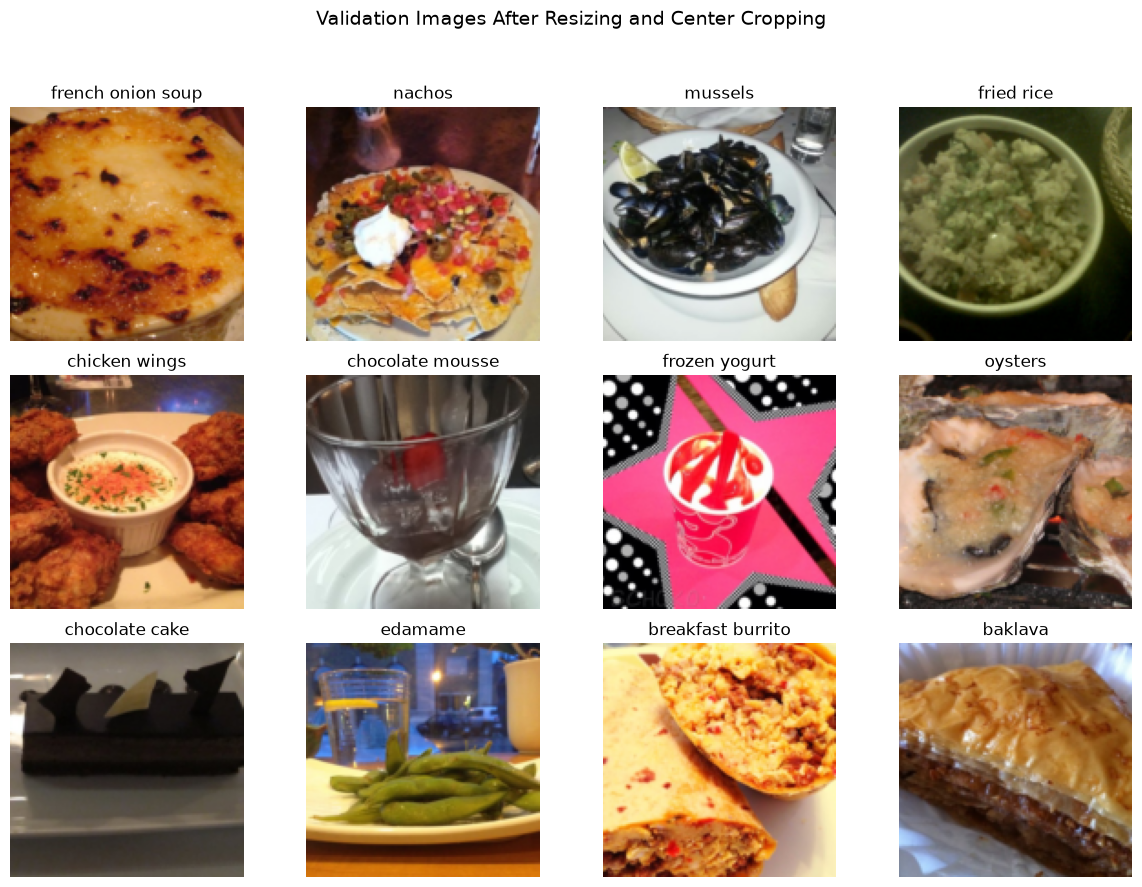

In [28]:
# Reverse normalization for display.
mean_tensor = torch.tensor(TRAIN_MEAN).view(1, 3, 1, 1)
std_tensor = torch.tensor(TRAIN_STD).view(1, 3, 1, 1)

display_images = (images * std_tensor + mean_tensor).clamp(0, 1)

fig, axes = plt.subplots(3, 4, figsize=(12, 9))

for position, ax in enumerate(axes.flat):
    image = display_images[position].permute(1, 2, 0).numpy()
    label = targets[position].item()

    ax.imshow(image)
    ax.set_title(ds_train.classes[label].replace("_", " "))
    ax.axis("off")

fig.suptitle("Validation Images After Resizing and Center Cropping", fontsize=14)
fig.tight_layout(rect=(0, 0, 1, 0.95))

fig.savefig(
    FIGURE_ROOT / "food101_validation_preprocessed_samples.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

## Baseline CNN architecture

The baseline is a compact convolutional neural network trained from scratch. Four convolutional blocks increase the channel count from
3 to 32, 64, 128, and 256. Each block uses a 3 × 3 convolution, batch normalization, ReLU activation, and 2 × 2 max pooling.

Convolutions learn spatial features, while pooling reduces spatial dimensions. Global average pooling summarizes each final feature map,
and a linear layer produces one logit for each of the 101 food classes. The model returns raw logits. Softmax is not applied inside the model because the cross-entropy loss operates directly on logits.

The main controlled comparison evaluates this baseline against a wider CNN that doubles the output channels in each convolutional block. All other training settings remain fixed for that comparison.

Supplementary experiments separately investigate label smoothing in the baseline, dropout in the wider CNN, and an increased maximum training budget for the wider CNN with dropout.

In [29]:
class FoodCNN(nn.Module):
    """Classify RGB food images using four convolutional blocks.

    Parameters
    ----------
    num_classes : int
        Number of output food categories.
    channels : tuple[int, ...]
        Output channel counts for the four convolutional blocks.
    """

    def __init__(
        self,
        num_classes: int = 101,
        channels: tuple[int, ...] = (32, 64, 128, 256),
        dropout_p: float = 0.0
    ) -> None:
        super().__init__()

        if len(channels) != 4 or any(width <= 0 for width in channels):
            raise ValueError("Provide four positive channel widths.")

        layer_channels = (3, *channels)
        layers = []

        for in_channels, out_channels in zip(layer_channels[:-1], layer_channels[1:]):
            layers.extend([
                nn.Conv2d(
                    in_channels,
                    out_channels,
                    kernel_size=3,
                    padding=1,
                    bias=False
                ),
                nn.BatchNorm2d(out_channels),
                nn.ReLU(),
                nn.MaxPool2d(kernel_size=2)
            ])

        self.features = nn.Sequential(*layers)
        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))
        self.dropout = nn.Dropout(p = dropout_p)
        self.classifier = nn.Linear(channels[-1], num_classes)

    def forward(self, images: torch.Tensor) -> torch.Tensor:
        """Return class logits for a batch of images.

        Parameters
        ----------
        images : torch.Tensor
            Floating-point input with shape (batch_size, 3, height, width).

        Returns
        -------
        torch.Tensor
            Raw logits with shape (batch_size, num_classes).
        """
        features = self.features(images)
        pooled = self.global_pool(features)
        flattened = torch.flatten(pooled, start_dim=1)
        flattened = self.dropout(flattened)
        return self.classifier(flattened)


torch.manual_seed(SEED)
model = FoodCNN(num_classes=len(ds_train.classes)).to(device)

parameter_count = sum(
    parameter.numel() for parameter in model.parameters()
    if parameter.requires_grad
)

print(model)
print(f"Trainable parameters: {parameter_count:,}")

FoodCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (13): B

In [30]:
model.eval()

with torch.no_grad():
    logits = model(images.to(device))

assert logits.shape == (images.shape[0], len(ds_train.classes))
assert torch.isfinite(logits).all().item()

print(f"Trainable parameters: {parameter_count:,}")
print("Input shape:", images.shape)
print("Output shape:", logits.shape)
print("Output device:", logits.device)

model.train();

Trainable parameters: 414,853
Input shape: torch.Size([32, 3, 128, 128])
Output shape: torch.Size([32, 101])
Output device: mps:0


## Training procedure

For each training batch, the model produces class logits and the loss measures their agreement with the labels. Backpropagation calculates gradients, and the optimizer updates the model parameters.

Epoch loss is averaged across images, accounting for the smaller final batch. Training accuracy records the proportion of correct predictions made during the epoch.

In [31]:
def train_one_epoch(
    model: nn.Module,
    loader: DataLoader,
    criterion: nn.Module,
    optimizer: torch.optim.Optimizer,
    device: torch.device
) -> dict[str, float]:
    """Train a model for one complete pass through a data loader.

    Parameters
    ----------
    model : nn.Module
        Neural network to train.
    loader : DataLoader
        Loader providing training image and label batches.
    criterion : nn.Module
        Loss function configured to return a mean batch loss.
    optimizer : torch.optim.Optimizer
        Optimizer used to update model parameters.
    device : torch.device
        Device on which model computation runs.

    Returns
    -------
    dict[str, float]
        Mean loss per image and top-1 accuracy as a fraction.
        Metrics reflect predictions made during parameter updates, rather than evaluation of the final epoch model.
    """
    model.train()

    total_loss = 0.0
    total_correct = 0
    total_images = 0

    for batch_images, batch_targets in tqdm(loader, desc="Training", leave=False):
        batch_images = batch_images.to(device)
        batch_targets = batch_targets.to(device)

        # Clear gradients left over from the previous batch.
        optimizer.zero_grad(set_to_none=True)

        # Forward pass and loss calculation.
        logits = model(batch_images)
        loss = criterion(logits, batch_targets)

        if not torch.isfinite(loss).item():
            raise RuntimeError("Training loss became non-finite.")

        # Compute gradients and update parameters.
        loss.backward()
        optimizer.step()

        batch_size = batch_targets.size(0)
        predictions = logits.detach().argmax(dim=1)

        total_loss += loss.item() * batch_size
        total_correct += (predictions == batch_targets).sum().item()
        total_images += batch_size

    return {
        "loss": total_loss / total_images,
        "accuracy": total_correct / total_images,
    }

## Validation procedure

After each training epoch, the model is evaluated on the validation split without random augmentation or parameter updates. Evaluation mode makes batch normalization use its stored running statistics. Gradient tracking is disabled during validation. Validation loss uses standard cross-entropy without label smoothing for both experimental configurations, providing a common comparison. Top-1 accuracy measures how often the highest-scoring class is correct.

In [32]:
@torch.no_grad()
def evaluate(
    model: nn.Module,
    loader: DataLoader,
    device: torch.device
) -> dict[str, float]:
    """Evaluate a model without updating its parameters.

    Parameters
    ----------
    model : nn.Module
        Neural network to evaluate.
    loader : DataLoader
        Loader providing evaluation image and label batches.
    device : torch.device
        Device on which model computation runs.

    Returns
    -------
    dict[str, float]
        Mean unsmoothed cross-entropy loss per image and
        top-1 accuracy as a fraction.
    """
    model.eval()
    criterion = nn.CrossEntropyLoss()

    total_loss = 0.0
    total_correct = 0
    total_images = 0

    for batch_images, batch_targets in tqdm(loader, desc="Evaluating", leave=False):
        batch_images = batch_images.to(device)
        batch_targets = batch_targets.to(device)

        logits = model(batch_images)
        loss = criterion(logits, batch_targets)

        if not torch.isfinite(loss).item():
            raise RuntimeError("Evaluation loss became non-finite.")

        batch_size = batch_targets.size(0)
        predictions = logits.argmax(dim=1)

        total_loss += loss.item() * batch_size
        total_correct += (predictions == batch_targets).sum().item()
        total_images += batch_size

    return {
        "loss": total_loss / total_images,
        "accuracy": total_correct / total_images,
    }

## Training pilot

A short pilot checks that the training and evaluation functions execute successfully and measures runtime on the selected device. The pilot uses 100 training batches and 50 validation batches. Adam starts with a learning rate of 0.001, and training uses standard cross-entropy without label smoothing. These are initial settings, not tuned choices. The pilot model will be discarded before the controlled experiments. Partial validation metrics are diagnostic and will not be reported as final performance.

In [33]:
# Reset randomness and create a separate model for the pilot.
torch.manual_seed(SEED)
train_generator.manual_seed(SEED)

pilot_model = FoodCNN(num_classes=len(ds_train.classes)).to(device)

pilot_criterion = nn.CrossEntropyLoss()
pilot_optimizer = torch.optim.Adam(pilot_model.parameters(), lr=0.001)

# Synchronize accelerator work so timing includes completed computation.
def synchronize_device(device: torch.device) -> None:
    """Wait for queued accelerator operations to complete.

    Parameters
    ----------
    device : torch.device
        Computation device to synchronize.

    Returns
    -------
    None
        Returns after queued work finishes; CPU requires no action.
    """
    if device.type == "mps":
        torch.mps.synchronize()
    elif device.type == "cuda":
        torch.cuda.synchronize(device)


synchronize_device(device)
start_time = perf_counter()

pilot_train_metrics = train_one_epoch(
    model=pilot_model,
    loader=islice(train_loader, 100),
    criterion=pilot_criterion,
    optimizer=pilot_optimizer,
    device=device
)

synchronize_device(device)
training_seconds = perf_counter() - start_time

start_time = perf_counter()

pilot_val_metrics = evaluate(
    model=pilot_model,
    loader=islice(val_loader, 50),
    device=device
)

synchronize_device(device)
validation_seconds = perf_counter() - start_time

print("Pilot training metrics:", pilot_train_metrics)
print("Pilot validation metrics:", pilot_val_metrics)
print(f"100 training batches: {training_seconds:.1f} seconds")
print(f"50 validation batches: {validation_seconds:.1f} seconds")

estimated_epoch_minutes = (training_seconds / 100 * len(train_loader) + validation_seconds / 50 * len(val_loader)) / 60

print(
    "Approximate full training + validation epoch: "
    f"{estimated_epoch_minutes:.1f} minutes"
)

Training: 0it [00:00, ?it/s]

Evaluating: 0it [00:00, ?it/s]

Pilot training metrics: {'loss': 4.553263449668885, 'accuracy': 0.0290625}
Pilot validation metrics: {'loss': 4.455972127914428, 'accuracy': 0.03}
100 training batches: 6.5 seconds
50 validation batches: 2.6 seconds
Approximate full training + validation epoch: 2.4 minutes


## Shared training procedure and initial label-smoothing experiment

The baseline and label-smoothing configurations use the same CNN, data split, preprocessing, batch size, optimizer, learning rate, and initial random seed. The training loss is the controlled change: standard cross-entropy versus cross-entropy with label smoothing of 0.1. Each configuration trains for a maximum of 30 epochs. Training stops after five consecutive epochs without a lower validation loss. Validation uses unsmoothed cross-entropy for both configurations. The checkpoint with the lowest validation loss is saved and restored. Training history is saved after each epoch. The official test partition
remains unused during training and checkpoint selection.

In [34]:
CHECKPOINT_FOLDER = Path(ROOT_FOLDER) / "checkpoints"
CHECKPOINT_FOLDER.mkdir(parents=True, exist_ok=True)

MAX_EPOCHS = 30
PATIENCE = 5


def run_experiment(
    run_name: str,
    label_smoothing: float,
    max_epochs: int = MAX_EPOCHS,
    patience: int = PATIENCE,
    channels: tuple[int, ...] = (32,64,128,256),
    dropout_p: float = 0.0
) -> tuple[nn.Module, pd.DataFrame]:
    """Train a fresh model with checkpointing and early stopping.

    Parameters
    ----------
    run_name : str
        Unique name used for checkpoint and history filenames.
    label_smoothing : float
        Smoothing strength used in the training cross-entropy loss.
    max_epochs : int
        Maximum number of training epochs.
    patience : int
        Consecutive epochs without lower validation loss before stopping
    channels : tuple[int, ...]
        Output channel counts for the four convolutional blocks.
    dropout_p : float
        Dropout probability applied before the linear classifier.

    Returns
    -------
    tuple[nn.Module, pd.DataFrame]
        Model restored to its best validation-loss checkpoint and
        a table containing metrics for all completed epochs.
    """
    checkpoint_path = CHECKPOINT_FOLDER / f"{run_name}_best.pt"
    history_path = CHECKPOINT_FOLDER / f"{run_name}_history.csv"

    # Load completed results when both saved files are available.
    if checkpoint_path.exists() and history_path.exists():
        checkpoint = torch.load(
            checkpoint_path,
            map_location="cpu",
            weights_only=True
        )
        saved_history = pd.read_csv(history_path)

        # Older baseline checkpoints did not record channel widths.
        saved_channels = tuple(
            checkpoint.get("channels", (32, 64, 128, 256))
        )

        # Existing checkpoints use "dropout"; accept either key.
        saved_dropout = checkpoint.get(
            "dropout_p",
            checkpoint.get("dropout", 0.0)
        )

        if (
            saved_channels != tuple(channels)
            or saved_dropout != dropout_p
            or checkpoint["label_smoothing"] != label_smoothing
            or checkpoint["seed"] != SEED
            or checkpoint["classes"] != list(ds_train.classes)
        ):
            raise ValueError(
                f"Saved settings do not match '{run_name}'. "
                "Use a new run name for a different configuration."
            )
        loaded_model = FoodCNN(
            num_classes=checkpoint["num_classes"],
            channels=saved_channels,
            dropout_p=saved_dropout
        )
        loaded_model.load_state_dict(checkpoint["model_state_dict"])
        loaded_model = loaded_model.to(device)
        loaded_model.eval()

        print(
            f"Loaded saved checkpoint for {run_name} | "
            f"epoch {checkpoint['epoch']} | "
            f"validation loss: {checkpoint['val_loss']:.4f} | "
            f"validation accuracy: {checkpoint['val_accuracy']:.2%}"
        )

        return loaded_model, saved_history

    # Do not overwrite an incomplete pair of saved files.
    if checkpoint_path.exists() or history_path.exists():
        raise FileExistsError(
            f"Only one saved results file exists for '{run_name}'. "
            "Check the checkpoint and history files before proceeding."
        )

    # Reset initialization, shuffle order, and augmentation randomness.
    torch.manual_seed(SEED)
    train_generator.manual_seed(SEED)

    experiment_model = FoodCNN(
        num_classes=len(ds_train.classes),
        channels=channels,
        dropout_p = dropout_p
    ).to(device)

    training_criterion = nn.CrossEntropyLoss(label_smoothing=label_smoothing)
    experiment_optimizer = torch.optim.Adam(experiment_model.parameters(), lr=0.001)

    history = []
    best_val_loss = float("inf")
    best_epoch = 0
    epochs_without_improvement = 0

    for epoch in range(1, max_epochs + 1):
        synchronize_device(device)
        start_time = perf_counter()

        train_metrics = train_one_epoch(
            model=experiment_model,
            loader=train_loader,
            criterion=training_criterion,
            optimizer=experiment_optimizer,
            device=device
        )

        val_metrics = evaluate(
            model=experiment_model,
            loader=val_loader,
            device=device
        )

        synchronize_device(device)
        runtime_minutes = (perf_counter() - start_time) / 60

        improved = val_metrics["loss"] < best_val_loss

        if improved:
            best_val_loss = val_metrics["loss"]
            best_epoch = epoch
            epochs_without_improvement = 0

            # Save CPU tensors so the weights can be loaded on any device.
            torch.save(
                {
                    "model_state_dict": {
                        name: tensor.detach().cpu().clone()
                        for name, tensor
                        in experiment_model.state_dict().items()
                    },
                    "epoch": epoch,
                    "val_loss": best_val_loss,
                    "val_accuracy": val_metrics["accuracy"],
                    "label_smoothing": label_smoothing,
                    "seed": SEED,
                    "num_classes": len(ds_train.classes),
                    "channels": list(channels),
                    "dropout": dropout_p,
                    "classes": list(ds_train.classes),
                    "image_size": IMAGE_SIZE,
                    "train_mean": list(TRAIN_MEAN),
                    "train_std": list(TRAIN_STD)
                },
                checkpoint_path
            )
        else:
            epochs_without_improvement += 1

        history.append({
            "epoch": epoch,
            "train_loss": train_metrics["loss"],
            "train_accuracy": train_metrics["accuracy"],
            "val_loss": val_metrics["loss"],
            "val_accuracy": val_metrics["accuracy"],
            "runtime_minutes": runtime_minutes,
            "improved": improved
        })

        pd.DataFrame(history).to_csv(history_path, index=False)

        print(
            f"{run_name} | epoch {epoch}/{max_epochs} | "
            f"train loss: {train_metrics['loss']:.4f} | "
            f"train accuracy: {train_metrics['accuracy']:.2%} | "
            f"val loss: {val_metrics['loss']:.4f} | "
            f"val accuracy: {val_metrics['accuracy']:.2%} | "
            f"patience: {epochs_without_improvement}/{patience}"
        )

        if epochs_without_improvement >= patience:
            print(f"Early stopping after epoch {epoch}.")
            break

    best_checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True
    )
    experiment_model.load_state_dict(best_checkpoint["model_state_dict"])
    experiment_model.eval()

    print(
        f"Restored epoch {best_epoch} | "
        f"validation loss: {best_val_loss:.4f} | "
        f"validation accuracy: "
        f"{best_checkpoint['val_accuracy']:.2%}"
    )

    return experiment_model, pd.DataFrame(history)

### Training and checkpoint reuse

All configurations were originally trained from scratch using the training procedure defined above. Their per-epoch histories and selected checkpoints are included in the repository.

For subsequent executions, the notebook loads existing checkpoints and histories to reproduce evaluation and plots without repeating training. The displayed history tables and learning curves record the original training runs; “Loaded saved checkpoint” messages describe the current execution.

When no saved results exist, the experiment runner trains the model and saves its history and best checkpoint. A new run name can be used to initiate a fresh training run while preserving existing results.

In [35]:
baseline_model, baseline_history_df = run_experiment(run_name="baseline_seed42", label_smoothing=0.0)

display(baseline_history_df)

Loaded saved checkpoint for baseline_seed42 | epoch 30 | validation loss: 1.9080 | validation accuracy: 52.62%


,epoch,train_loss,train_accuracy,val_loss,val_accuracy,runtime_minutes,improved
0,1,4.028520,0.093812,3.774015,0.131023,2.383420,True
1,2,3.476423,0.184373,3.578027,0.185083,2.378643,True
2,3,3.145271,0.248993,3.114395,0.254719,2.385423,True
3,4,2.899727,0.301040,2.884053,0.304092,2.403277,True
4,5,2.715800,0.338828,2.762718,0.332937,2.392178,True
5,6,2.572375,0.370561,2.582400,0.372013,2.386328,True
6,7,2.456675,0.398630,2.632941,0.351815,2.387501,False
7,8,2.357660,0.419785,2.562121,0.374785,2.383843,True
8,9,2.280584,0.436386,2.437076,0.398218,2.410594,True
9,10,2.207362,0.451584,2.430591,0.419604,2.399197,True


In [36]:
smoothed_model, smoothed_history_df = run_experiment(run_name="label_smoothing_01_seed42", label_smoothing=0.1)

display(smoothed_history_df)

Loaded saved checkpoint for label_smoothing_01_seed42 | epoch 26 | validation loss: 1.9220 | validation accuracy: 52.83%


,epoch,train_loss,train_accuracy,val_loss,val_accuracy,runtime_minutes,improved
0,1,4.146929,0.094439,3.758232,0.135050,2.374739,True
1,2,3.704685,0.187508,3.414983,0.201848,2.397170,True
2,3,3.441130,0.253300,3.057468,0.268383,2.381888,True
3,4,3.245645,0.305759,2.856902,0.317822,2.359718,True
4,5,3.099162,0.346997,2.755954,0.335578,2.351992,True
5,6,2.986540,0.380248,2.519788,0.389703,2.382325,True
6,7,2.894622,0.406172,2.745560,0.337822,2.400953,False
7,8,2.819187,0.427591,2.503973,0.397756,2.376785,True
8,9,2.757477,0.445644,2.497955,0.397096,2.382876,True
9,10,2.704000,0.461370,2.329150,0.439076,2.402929,True


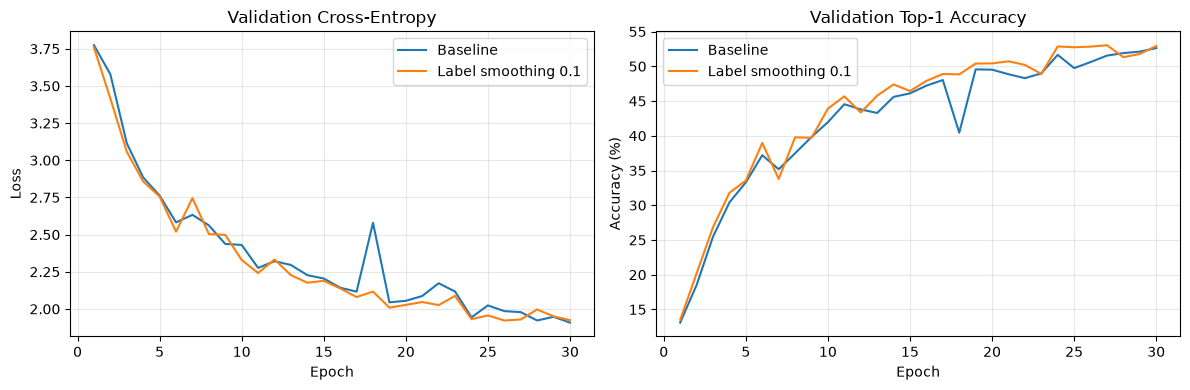

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for history, name in [
    (baseline_history_df, "Baseline"),
    (smoothed_history_df, "Label smoothing 0.1")
]:
    axes[0].plot(
        history["epoch"],
        history["val_loss"],
        label=name
    )

    axes[1].plot(
        history["epoch"],
        history["val_accuracy"] * 100,
        label=name
    )

axes[0].set_title("Validation Cross-Entropy")
axes[0].set_ylabel("Loss")

axes[1].set_title("Validation Top-1 Accuracy")
axes[1].set_ylabel("Accuracy (%)")

for ax in axes:
    ax.set_xlabel("Epoch")
    ax.legend()
    ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig(
    FIGURE_ROOT / "baseline_vs_label_smoothing_validation_curves.png",
    dpi = 300,
    bbox_inches="tight"
)
plt.show()

## Final test evaluation

Both configurations are evaluated on the official Food-101 test partition using checkpoints selected by minimum validation loss. Test images use the same deterministic resizing, center cropping, and training-derived normalization as validation images. Test cross-entropy and top-1 accuracy are reported for both models. Test results are not used to adjust training settings or select checkpoints.

In [38]:
# Use the existing validation transform for identical test preprocessing.
test_dataset = Food101(
    root=str(DATA_FOLDER),
    split="test",
    transform=val_transform,
    download=False
)

assert test_dataset.classes == ds_train.classes
assert len(test_dataset) == 25250

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_results = []

for name, selected_model, history in [
    ("Baseline", baseline_model, baseline_history_df),
    ("Label smoothing 0.1", smoothed_model, smoothed_history_df)
]:
    # The runner already restored the minimum-validation-loss checkpoint.
    best_row = history.loc[history["val_loss"].idxmin()]

    test_metrics = evaluate(
        model=selected_model,
        loader=test_loader,
        device=device
    )

    test_results.append({
        "configuration": name,
        "selected_epoch": int(best_row["epoch"]),
        "validation_loss": best_row["val_loss"],
        "validation_accuracy": best_row["val_accuracy"],
        "test_loss": test_metrics["loss"],
        "test_accuracy": test_metrics["accuracy"]
    })

test_results_df = pd.DataFrame(test_results)
display(test_results_df)

Evaluating:   0%|          | 0/790 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/790 [00:00<?, ?it/s]

,configuration,selected_epoch,validation_loss,validation_accuracy,test_loss,test_accuracy
0,Baseline,30,1.907953,0.526205,1.642915,0.573941
1,Label smoothing 0.1,26,1.922037,0.528317,1.689052,0.582099


## Architectural experiment: Wider CNN

The modified CNN doubles the output channels in each convolutional block from [32, 64, 128, 256] to [64, 128, 256, 512].

Channel width is the single architectural change. Both configurations retain four convolutional blocks, batch normalization, ReLU, max pooling, global average pooling, and a linear classifier.

The data split, preprocessing, batch size, optimizer, learning rate, seed, maximum training budget, and early-stopping rule remain identical. Both models use cross-entropy without label smoothing.

The comparison investigates whether additional feature capacity improves classification and how it affects generalization, parameter count, and training runtime.

In [39]:
BASELINE_CHANNELS = (32, 64, 128, 256)
WIDER_CHANNELS = (64, 128, 256, 512)

torch.manual_seed(SEED)

wider_check_model = FoodCNN(
    num_classes=len(ds_train.classes),
    channels=WIDER_CHANNELS
).to(device)

wider_check_model.eval()

with torch.no_grad():
    wider_logits = wider_check_model(images.to(device))

assert wider_logits.shape == (images.shape[0], len(ds_train.classes))
assert torch.isfinite(wider_logits).all().item()

wider_parameter_count = sum(
    parameter.numel()
    for parameter in wider_check_model.parameters()
    if parameter.requires_grad
)

print(f"Wider model parameters: {wider_parameter_count:,}")
print("Output shape:", wider_logits.shape)

# Release the temporary model before the training run.
del wider_check_model, wider_logits

Wider model parameters: 1,603,749
Output shape: torch.Size([32, 101])


In [40]:
wider_model, wider_history_df = run_experiment(
    run_name="wider_cnn_seed42",
    label_smoothing=0.0,
    channels=WIDER_CHANNELS
)

display(wider_history_df)

Loaded saved checkpoint for wider_cnn_seed42 | epoch 30 | validation loss: 1.7141 | validation accuracy: 58.01%


,epoch,train_loss,train_accuracy,val_loss,val_accuracy,runtime_minutes,improved
0,1,4.030461,0.093548,3.773661,0.139010,3.456156,True
1,2,3.393875,0.200561,3.479157,0.214323,3.413968,True
2,3,2.998094,0.279274,3.037760,0.271023,3.452057,True
3,4,2.704932,0.343828,2.713101,0.345809,3.455770,True
4,5,2.491262,0.390149,2.562800,0.375842,3.452652,True
5,6,2.313488,0.428746,2.440982,0.408647,3.451460,True
6,7,2.177347,0.458416,2.716644,0.346535,3.455010,False
7,8,2.063715,0.485512,2.310413,0.433003,3.458931,True
8,9,1.964219,0.506782,2.177344,0.459076,3.486441,True
9,10,1.877326,0.528119,2.030887,0.496436,3.499323,True


In [41]:
wider_test_metrics = evaluate(model=wider_model, loader=test_loader, device=device)

best_row = wider_history_df.loc[wider_history_df["val_loss"].idxmin()]

wider_result = pd.DataFrame([{
    "configuration": "Wider CNN",
    "selected_epoch": int(best_row["epoch"]),
    "validation_loss": best_row["val_loss"],
    "validation_accuracy": best_row["val_accuracy"],
    "test_loss": wider_test_metrics["loss"],
    "test_accuracy": wider_test_metrics["accuracy"]
}])

# Replace any previous wider-model row to avoid duplicates.
test_results_df = pd.concat(
    [
        test_results_df[test_results_df["configuration"] != "Wider CNN"],
        wider_result
    ],
    ignore_index=True
)

display(test_results_df)

Evaluating:   0%|          | 0/790 [00:00<?, ?it/s]

,configuration,selected_epoch,validation_loss,validation_accuracy,test_loss,test_accuracy
0,Baseline,30,1.907953,0.526205,1.642915,0.573941
1,Label smoothing 0.1,26,1.922037,0.528317,1.689052,0.582099
2,Wider CNN,30,1.714144,0.580066,1.420094,0.635327


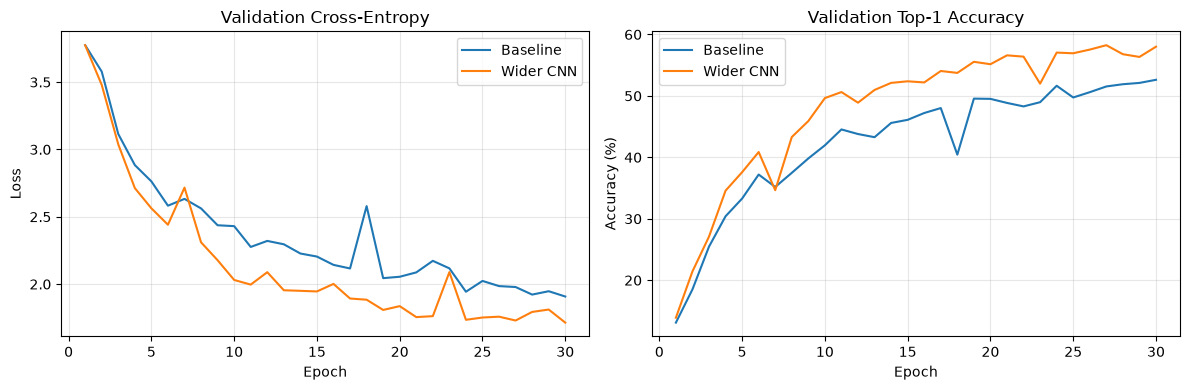

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for history, name in [
    (baseline_history_df, "Baseline"),
    (wider_history_df, "Wider CNN")
]:
    axes[0].plot(
        history["epoch"], history["val_loss"], label=name
    )
    axes[1].plot(
        history["epoch"],
        history["val_accuracy"] * 100,
        label=name
    )

axes[0].set_title("Validation Cross-Entropy")
axes[0].set_ylabel("Loss")

axes[1].set_title("Validation Top-1 Accuracy")
axes[1].set_ylabel("Accuracy (%)")

for ax in axes:
    ax.set_xlabel("Epoch")
    ax.legend()
    ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig(
    FIGURE_ROOT / "baseline_vs_wider_cnn_validation_curves.png",
    dpi = 300,
    bbox_inches="tight"
)
plt.show()

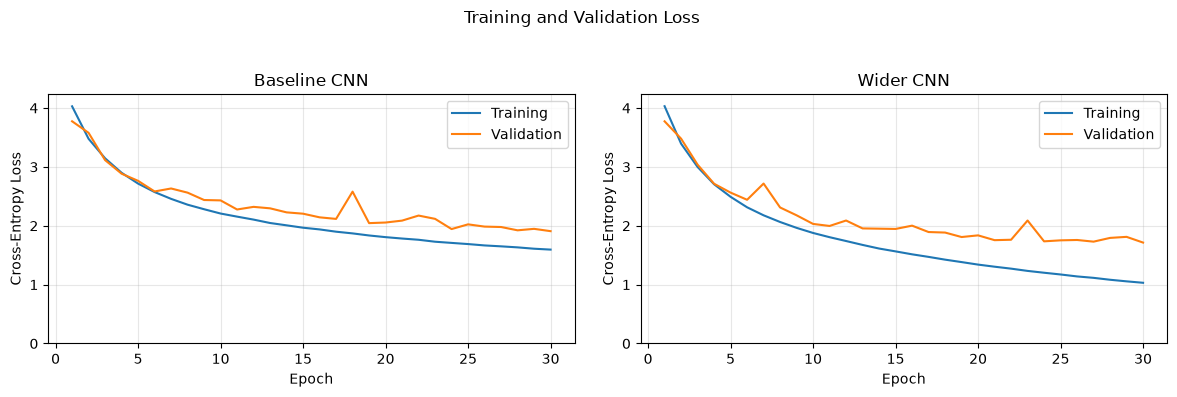

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, history, name in [
    (axes[0], baseline_history_df, "Baseline CNN"),
    (axes[1], wider_history_df, "Wider CNN")
]:
    ax.plot(
        history["epoch"],
        history["train_loss"],
        label="Training"
    )
    ax.plot(
        history["epoch"],
        history["val_loss"],
        label="Validation"
    )

    ax.set_title(name)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Cross-Entropy Loss")
    ax.legend()
    ax.grid(alpha=0.3)

# Use the same vertical scale to make the panels easier to compare.
upper_limit = max(
    baseline_history_df[["train_loss", "val_loss"]].to_numpy().max(),
    wider_history_df[["train_loss", "val_loss"]].to_numpy().max()
)

for ax in axes:
    ax.set_ylim(0, upper_limit * 1.05)

fig.suptitle("Training and Validation Loss")
fig.tight_layout(rect=(0, 0, 1, 0.94))

fig.savefig(
    FIGURE_ROOT / "baseline_and_wider_cnn_training_validation_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Class-level error analysis

The wider CNN is examined using per-class recall and frequent true-class/predicted-class confusion pairs.

Recall measures the proportion of test images in each food category that are classified correctly. Error analysis describes the evaluated
model's limitations; it is not used to tune the model on the test set.

In [44]:
from sklearn.metrics import confusion_matrix

# Collect predictions in the test loader's fixed order.
wider_model.eval()
true_labels = []
predicted_labels = []

with torch.no_grad():
    for batch_images, batch_targets in tqdm(
        test_loader,
        desc="Collecting test predictions"
    ):
        logits = wider_model(batch_images.to(device))
        predictions = logits.argmax(dim=1)

        true_labels.extend(batch_targets.tolist())
        predicted_labels.extend(predictions.cpu().tolist())

class_names = list(ds_train.classes)
num_classes = len(class_names)

cm = confusion_matrix(
    true_labels,
    predicted_labels,
    labels=list(range(num_classes))
)

class_support = cm.sum(axis=1)
assert (class_support == 250).all()

class_results_df = pd.DataFrame({
    "class": class_names,
    "test_images": class_support,
    "correct": cm.diagonal(),
    "recall": cm.diagonal() / class_support
})

print("Lowest-recall classes:")
display(class_results_df.nsmallest(10, "recall"))

print("Highest-recall classes:")
display(class_results_df.nlargest(10, "recall"))

# Remove correct predictions to rank only confusion pairs.
error_counts = cm.copy()
np.fill_diagonal(error_counts, 0)

true_ids, predicted_ids = np.nonzero(error_counts)

confusion_pairs_df = pd.DataFrame({
    "true_class": [class_names[i] for i in true_ids],
    "predicted_class": [class_names[i] for i in predicted_ids],
    "count": error_counts[true_ids, predicted_ids]
}).sort_values("count", ascending=False)

print("Most frequent confusion pairs:")
display(confusion_pairs_df.head(10))

Lowest-recall classes:


,class,test_images,correct,recall
0,apple_pie,250,49,0.196
22,chocolate_mousse,250,62,0.248
77,pork_chop,250,66,0.264
93,steak,250,70,0.280
99,tuna_tartare,250,79,0.316
26,crab_cakes,250,81,0.324
50,grilled_salmon,250,87,0.348
66,nachos,250,89,0.356
9,breakfast_burrito,250,99,0.396
53,hamburger,250,101,0.404


Highest-recall classes:


,class,test_images,correct,recall
33,edamame,250,242,0.968
54,hot_and_sour_soup,250,226,0.904
64,miso_soup,250,224,0.896
60,lobster_bisque,250,220,0.880
65,mussels,250,217,0.868
75,pho,250,216,0.864
11,caesar_salad,250,213,0.852
83,red_velvet_cake,250,212,0.848
30,deviled_eggs,250,211,0.844
88,seaweed_salad,250,211,0.844


Most frequent confusion pairs:


,true_class,predicted_class,count
1979,hamburger,pulled_pork_sandwich,67
3272,steak,filet_mignon,64
3046,samosa,spring_rolls,42
1652,fried_rice,risotto,38
2435,nachos,tacos,36
2757,pork_chop,filet_mignon,35
895,chocolate_mousse,chocolate_cake,31
3,apple_pie,bread_pudding,30
2309,macaroni_and_cheese,risotto,29
1757,gnocchi,ravioli,27


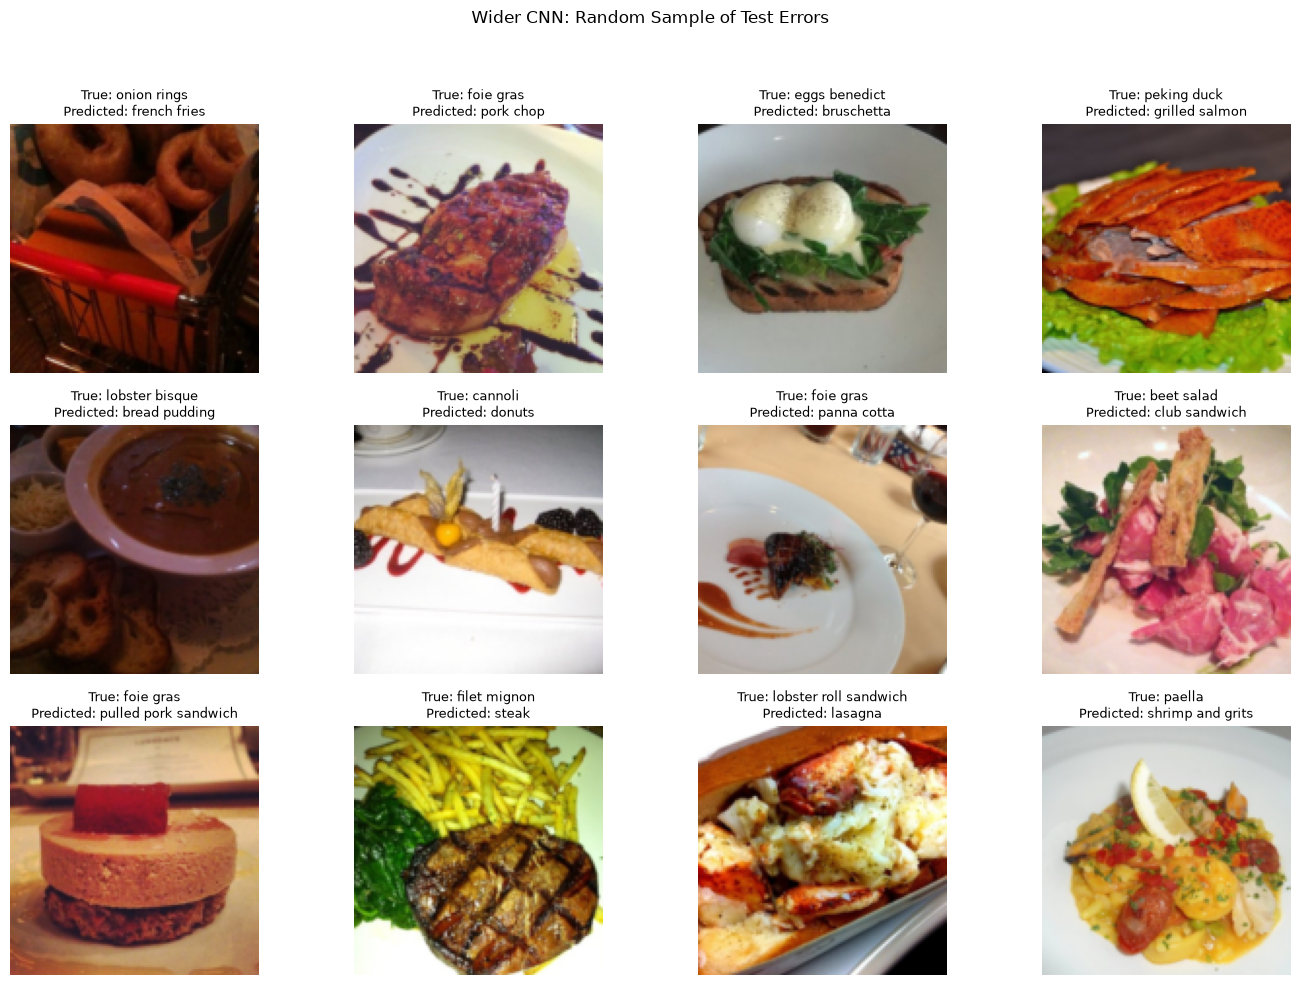

In [45]:
true_array = np.asarray(true_labels)
predicted_array = np.asarray(predicted_labels)

error_indices = np.flatnonzero(true_array != predicted_array)

# Reproducibly sample errors rather than selecting only striking examples.
rng = np.random.default_rng(SEED)
sample_indices = rng.choice(
    error_indices,
    size=min(12, len(error_indices)),
    replace=False
)

mean_tensor = torch.tensor(TRAIN_MEAN).view(3, 1, 1)
std_tensor = torch.tensor(TRAIN_STD).view(3, 1, 1)

fig, axes = plt.subplots(3, 4, figsize=(14, 10))

for ax, index in zip(axes.flat, sample_indices):
    image_tensor, target = test_dataset[int(index)]

    # Reverse normalization to display the input seen by the model.
    display_image = (
        image_tensor * std_tensor + mean_tensor
    ).clamp(0, 1)

    prediction = int(predicted_array[index])

    ax.imshow(display_image.permute(1, 2, 0).numpy())
    ax.set_title(
        f"True: {class_names[target].replace('_', ' ')}\n"
        f"Predicted: {class_names[prediction].replace('_', ' ')}",
        fontsize=9
    )
    ax.axis("off")

for ax in list(axes.flat)[len(sample_indices):]:
    ax.axis("off")

fig.suptitle("Wider CNN: Random Sample of Test Errors")
fig.tight_layout(rect=(0, 0, 1, 0.95))

fig.savefig(
    FIGURE_ROOT / "wider_cnn_test_misclassification_samples.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Interpretation of sampled errors

The sampled errors illustrate difficulties distinguishing visually similar foods and recognizing categories with varied presentations. For example, filet mignon was predicted as steak, while eggs benedict on bread was predicted as bruschetta. Three foie-gras examples differed substantially in appearance and received different incorrect predictions.

Some images also contain dim lighting, prominent garnishes, or accompanying foods that may complicate classification. These observations suggest possible challenges but do not establish which features drove the model's decisions. The grid is a reproducible random sample of errors, rather than a representative sample of all test images.

## Supplementary experiment: dropout in the wider CNN

This experiment adds dropout with probability 0.3 after global average pooling and flattening, immediately before the linear classifier. The comparison investigates whether dropout improves generalization relative to the existing wider CNN. Channel widths, image preprocessing, augmentation, optimizer, learning rate, batch size, seed, maximum epochs, and early-stopping procedure remain unchanged. Label smoothing is disabled.

The dropout probability is a fixed exploratory choice, not a tuned value. Checkpoint selection continues to use minimum validation cross-entropy.

In [46]:
dropout_model, dropout_history_df = run_experiment(
    run_name="wider_dropout03_seed42",
    label_smoothing=0.0,
    channels=WIDER_CHANNELS,
    dropout_p=0.3
)

display(dropout_history_df)

Loaded saved checkpoint for wider_dropout03_seed42 | epoch 29 | validation loss: 1.6580 | validation accuracy: 58.58%


,epoch,train_loss,train_accuracy,val_loss,val_accuracy,runtime_minutes,improved
0,1,4.090906,0.084208,3.805226,0.125413,3.552614,True
1,2,3.525488,0.173812,3.498567,0.204488,3.443320,True
2,3,3.180463,0.241848,3.111905,0.252475,3.507558,True
3,4,2.910333,0.296254,2.734694,0.335446,3.447846,True
4,5,2.708394,0.341799,2.592739,0.365083,3.449598,True
5,6,2.542343,0.376650,2.483394,0.391221,3.477098,True
6,7,2.412935,0.406601,2.703079,0.344554,3.447530,False
7,8,2.300899,0.431584,2.295228,0.437756,3.471392,True
8,9,2.211798,0.450710,2.183500,0.460924,3.491902,True
9,10,2.130377,0.466964,2.163922,0.466139,3.516189,True


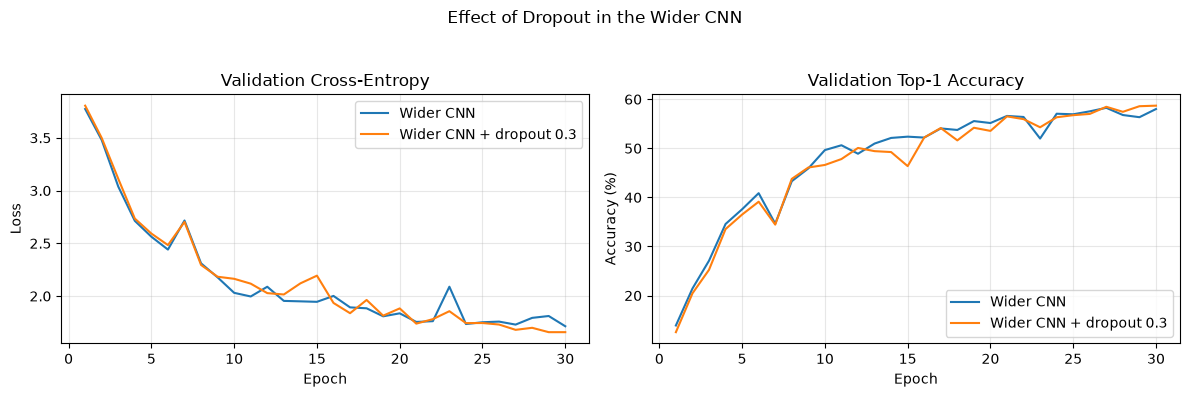

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for history, name in [
    (wider_history_df, "Wider CNN"),
    (dropout_history_df, "Wider CNN + dropout 0.3")
]:
    axes[0].plot(
        history["epoch"],
        history["val_loss"],
        label=name
    )
    axes[1].plot(
        history["epoch"],
        history["val_accuracy"] * 100,
        label=name
    )

axes[0].set_title("Validation Cross-Entropy")
axes[0].set_ylabel("Loss")

axes[1].set_title("Validation Top-1 Accuracy")
axes[1].set_ylabel("Accuracy (%)")

for ax in axes:
    ax.set_xlabel("Epoch")
    ax.legend()
    ax.grid(alpha=0.3)

fig.suptitle("Effect of Dropout in the Wider CNN")
fig.tight_layout(rect=(0, 0, 1, 0.94))

fig.savefig(
    FIGURE_ROOT / "wider_cnn_vs_dropout_validation_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [48]:
dropout_test_metrics = evaluate(model=dropout_model, loader=test_loader, device=device)

best_row = dropout_history_df.loc[dropout_history_df["val_loss"].idxmin()]

dropout_result = pd.DataFrame([{
    "configuration": "Wider CNN + dropout 0.3",
    "selected_epoch": int(best_row["epoch"]),
    "validation_loss": best_row["val_loss"],
    "validation_accuracy": best_row["val_accuracy"],
    "test_loss": dropout_test_metrics["loss"],
    "test_accuracy": dropout_test_metrics["accuracy"]
}])

test_results_df = pd.concat(
    [
        test_results_df[
            test_results_df["configuration"]
            != "Wider CNN + dropout 0.3"
        ],
        dropout_result
    ],
    ignore_index=True
)

display(test_results_df)

Evaluating:   0%|          | 0/790 [00:00<?, ?it/s]

,configuration,selected_epoch,validation_loss,validation_accuracy,test_loss,test_accuracy
0,Baseline,30,1.907953,0.526205,1.642915,0.573941
1,Label smoothing 0.1,26,1.922037,0.528317,1.689052,0.582099
2,Wider CNN,30,1.714144,0.580066,1.420094,0.635327
3,Wider CNN + dropout 0.3,29,1.658033,0.585809,1.388689,0.636990


## Supplementary experiment: Increased training budget

The wider CNN with dropout probability 0.3 is trained with a maximum budget of 60 epochs instead of 30. The maximum epoch count is the only setting changed from the earlier dropout experiment.

Architecture, preprocessing, augmentation, optimizer, learning rate, batch size, seed, checkpoint selection, and early-stopping patience remain unchanged. The experiment starts from scratch because earlier checkpoints do not contain the optimizer and random states required for exact continuation.

Validation loss determines early stopping and checkpoint selection. The run may stop before epoch 60 if five consecutive epochs fail to improve validation loss. Earlier test results have already been observed; they are not used to select this run's checkpoint.

In [49]:
dropout60_model, dropout60_history_df = run_experiment(
    run_name="wider_dropout03_60epochs_seed42",
    label_smoothing=0.0,
    channels=WIDER_CHANNELS,
    dropout_p=0.3,
    max_epochs=60,
    patience=5
)

display(dropout60_history_df)

Loaded saved checkpoint for wider_dropout03_60epochs_seed42 | epoch 39 | validation loss: 1.5948 | validation accuracy: 60.20%


,epoch,train_loss,train_accuracy,val_loss,val_accuracy,runtime_minutes,improved
0,1,4.090906,0.084208,3.805226,0.125413,3.498126,True
1,2,3.525488,0.173812,3.498567,0.204488,3.516992,True
2,3,3.180463,0.241848,3.111905,0.252475,3.523475,True
3,4,2.910333,0.296254,2.734694,0.335446,3.501688,True
4,5,2.708394,0.341799,2.592739,0.365083,3.499294,True
5,6,2.542343,0.376650,2.483394,0.391221,3.531684,True
6,7,2.412935,0.406601,2.703079,0.344554,3.536831,False
7,8,2.300899,0.431584,2.295228,0.437756,3.525712,True
8,9,2.211798,0.450710,2.183500,0.460924,3.554879,True
9,10,2.130377,0.466964,2.163922,0.466139,3.670870,True


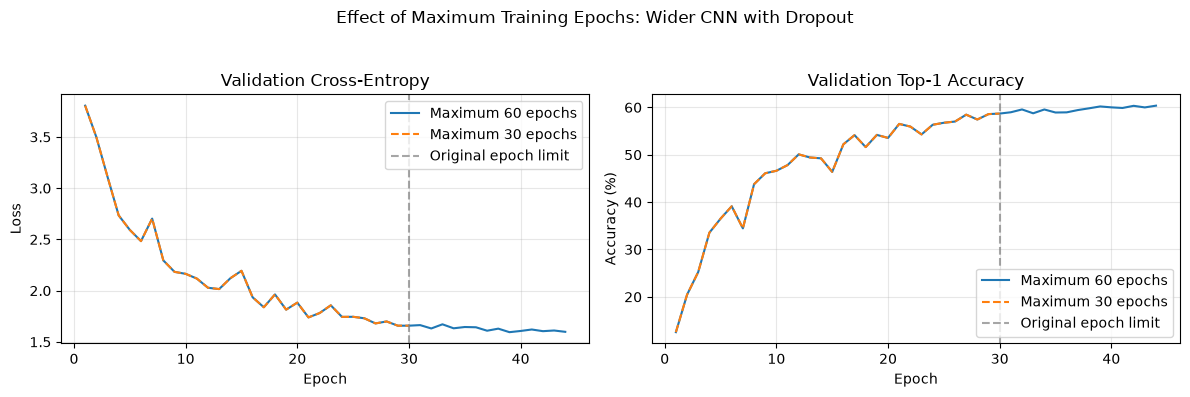

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for history, name, line_style in [
    (dropout60_history_df, "Maximum 60 epochs", "-"),
    (dropout_history_df, "Maximum 30 epochs", "--")
]:
    axes[0].plot(
        history["epoch"],
        history["val_loss"],
        label=name,
        linestyle=line_style
    )
    axes[1].plot(
        history["epoch"],
        history["val_accuracy"] * 100,
        label=name,
        linestyle=line_style
    )

axes[0].set_title("Validation Cross-Entropy")
axes[0].set_ylabel("Loss")

axes[1].set_title("Validation Top-1 Accuracy")
axes[1].set_ylabel("Accuracy (%)")

for ax in axes:
    ax.axvline(
        30,
        color="gray",
        linestyle="--",
        alpha=0.7,
        label="Original epoch limit"
    )
    ax.set_xlabel("Epoch")
    ax.legend()
    ax.grid(alpha=0.3)

fig.suptitle("Effect of Maximum Training Epochs: Wider CNN with Dropout")
fig.tight_layout(rect=(0, 0, 1, 0.94))

fig.savefig(
    FIGURE_ROOT / "dropout_30_vs_60_max_epochs_validation_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

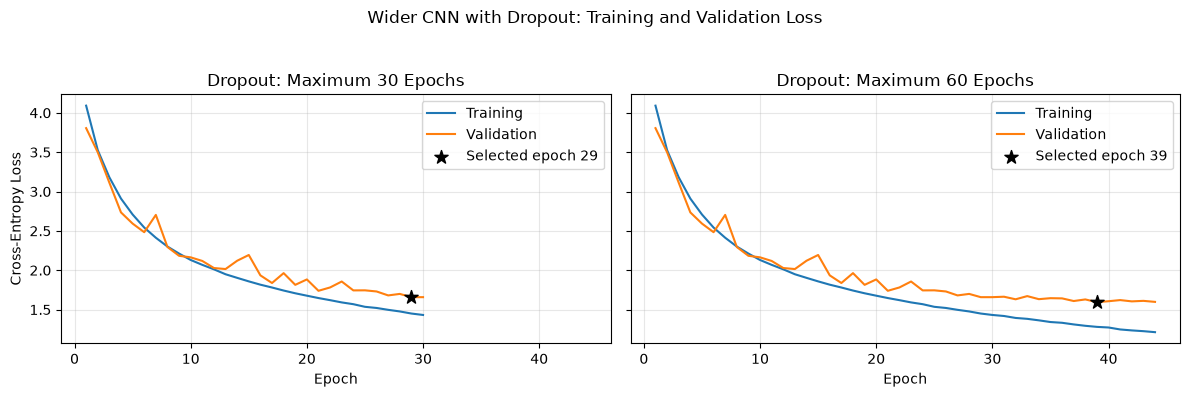

In [51]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True, sharey=True)

for ax, history, name in [
    (axes[0], dropout_history_df, "Dropout: Maximum 30 Epochs"),
    (axes[1], dropout60_history_df, "Dropout: Maximum 60 Epochs")
]:
    ax.plot(
        history["epoch"],
        history["train_loss"],
        label="Training"
    )
    ax.plot(
        history["epoch"],
        history["val_loss"],
        label="Validation"
    )

    best_row = history.loc[history["val_loss"].idxmin()]

    ax.scatter(
        best_row["epoch"],
        best_row["val_loss"],
        color="black",
        marker="*",
        s=100,
        zorder=3,
        label=f"Selected epoch {int(best_row['epoch'])}"
    )

    ax.set_title(name)
    ax.set_xlabel("Epoch")
    ax.legend()
    ax.grid(alpha=0.3)

axes[0].set_ylabel("Cross-Entropy Loss")

fig.suptitle("Wider CNN with Dropout: Training and Validation Loss")
fig.tight_layout(rect=(0, 0, 1, 0.94))

fig.savefig(
    FIGURE_ROOT / "dropout_training_validation_loss_by_epoch_limit.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [52]:
dropout60_test_metrics = evaluate(model=dropout60_model, loader=test_loader, device=device)

best_row = dropout60_history_df.loc[dropout60_history_df["val_loss"].idxmin()]

run_label = "Wider CNN + dropout 0.3, max 60 epochs"

extended_result = pd.DataFrame([{
    "configuration": run_label,
    "selected_epoch": int(best_row["epoch"]),
    "validation_loss": best_row["val_loss"],
    "validation_accuracy": best_row["val_accuracy"],
    "test_loss": dropout60_test_metrics["loss"],
    "test_accuracy": dropout60_test_metrics["accuracy"]
}])

test_results_df = pd.concat(
    [
        test_results_df[
            test_results_df["configuration"] != run_label
        ],
        extended_result
    ],
    ignore_index=True
)

display(test_results_df)

Evaluating:   0%|          | 0/790 [00:00<?, ?it/s]

,configuration,selected_epoch,validation_loss,validation_accuracy,test_loss,test_accuracy
0,Baseline,30,1.907953,0.526205,1.642915,0.573941
1,Label smoothing 0.1,26,1.922037,0.528317,1.689052,0.582099
2,Wider CNN,30,1.714144,0.580066,1.420094,0.635327
3,Wider CNN + dropout 0.3,29,1.658033,0.585809,1.388689,0.636990
4,"Wider CNN + dropout 0.3, max 60 epochs",39,1.594761,0.601980,1.323959,0.656317


## Notebook Summary

This project classified images into 101 Food-101 categories using convolutional neural networks implemented in PyTorch and trained from scratch.

The main controlled experiment doubled the baseline CNN's channel widths, improving test accuracy from 57.39% to 63.53% while requiring approximately 3.87 times as many trainable parameters and longer training epochs.

Additional controlled experiments achieved 58.21% test accuracy by adding label smoothing to the baseline and 63.70% by adding dropout to the wider CNN.

Increasing the wider dropout model's maximum training epochs from 30 to 60 improved test accuracy to 65.63% and reduced test cross-entropy to 1.3240; early stopping ended training at epoch 44, and the checkpoint with the lowest validation loss, from epoch 39, was restored.

Class-level analysis of the wider CNN without dropout revealed substantial variation in recall and frequent confusion between visually similar foods.

These findings reflect a single training seed, and later experiments were introduced after earlier test results had been observed, making those comparisons exploratory despite consistent checkpoint selection using validation loss.